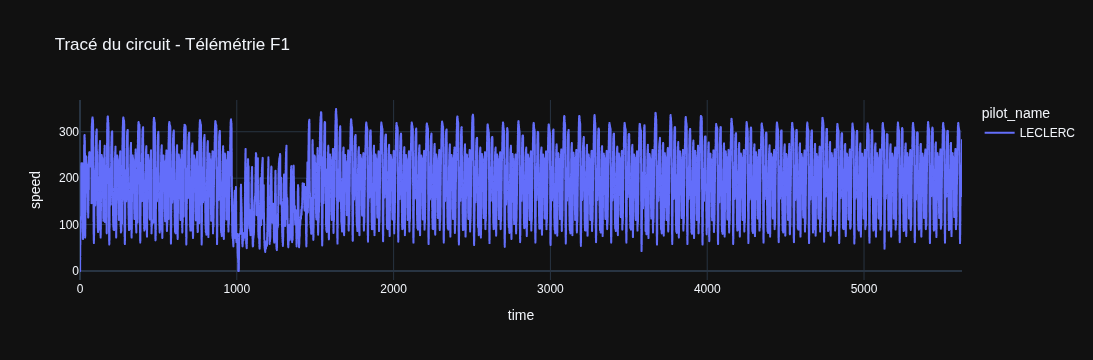

In [8]:
import duckdb
import plotly.express as px

# 1. Connexion
con = duckdb.connect(database='md:')

# 2. Définition du chemin
path_parquet = "/home/alexandre/Projects/Perso/Data_Engineer/F1/data/silver/f1_data.parquet"

# Création d'une vue pour simplifier les requêtes suivantes
con.execute(f"CREATE VIEW IF NOT EXISTS telemetry_view AS SELECT * FROM read_parquet('{path_parquet}')")

# 3. Extraction des données (on filtre sur UN pilote pour commencer, sinon c'est illisible)
# On ne met PAS de GROUP BY ici, on veut la trajectoire complète
df = con.execute("""
    SELECT pilot_name, speed,time
    FROM telemetry_view
    WHERE pilot_name = 'LECLERC'
    ORDER BY date ASC
""").df()

# 4. Création du visuel (Tracé du circuit)
fig = px.line(
    df,
    x='time',
    y='speed',
    color='pilot_name',
    title="Tracé du circuit - Télémétrie F1"
)

# 5. L'astuce cruciale pour ne pas avoir un circuit déformé
fig.update_layout(template="plotly_dark") # Look F1 direct

fig.show()

In [1]:
# Calcul de la vitesse moyenne

  pilot_name   avg_speed  max_speed  min_speed
0  ANTONELLI  194.796043      339.0        0.0
1    LECLERC  191.990352      349.0        0.0


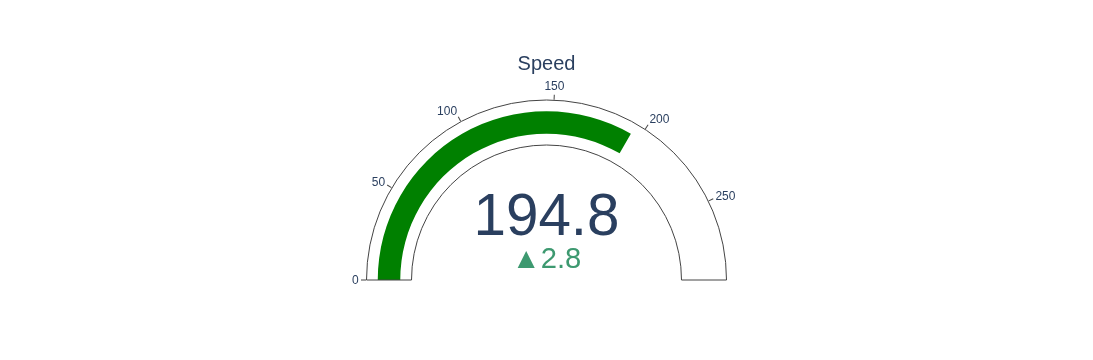

In [26]:
import plotly.graph_objects as go

df = con.execute("""
    SELECT pilot_name, AVG(speed) AS avg_speed, MAX(speed) as max_speed, MIN(speed) as min_speed
    FROM telemetry_view
    GROUP BY pilot_name
    ORDER BY pilot_name
""").df()

print(df)

avg_speed = df.iloc[0]['avg_speed']
speed_stats_lec = df[df['pilot_name'] == 'LECLERC'].iloc[0]



import plotly.graph_objects as go

fig = go.Figure(go.Indicator(
    mode = "gauge+number+delta",
    value = avg_speed,
    delta = {'reference': speed_stats_lec['avg_speed']},
    title = {'text': "Speed"},
    domain = {'x': [0, 1], 'y': [0, 1]}
))

fig.show()


In [27]:
#Test 

In [41]:
import plotly.graph_objects as go

df = con.execute("""
    SELECT DISTINCT position_x, position_y
    FROM telemetry_view
    WHERE speed > 190.0
    ORDER BY pilot_name
""").df()

fig = go.Figure(go.Scatter(
    x=df['position_x'],
    y=df['position_y'],
    mode='lines',  # ou 'lines' pour un tracé continu
    marker=dict(
        color=df['speed'],        # encode la vitesse en couleur
        colorscale='RdYlGn',      # rouge = lent, vert = rapide
        colorbar=dict(title='Speed (km/h)'),
        size=3
    )
))

fig.show()

KeyError: 'speed'

In [46]:
import fastf1

year = 2026
wknd = 2
ses = 'R'
driver = 'LEC'


session = fastf1.get_session(year, wknd, ses)
weekend = session.event
session.load()
lap = session.laps.pick_drivers(driver).pick_fastest()

print(lap['Time'])


core           INFO 	Loading data for Chinese Grand Prix - Race [v3.8.1]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core        WARNING 	Driver 12 completed the race distance 00:00.022000 before the recorded end of the session.
core           INFO 	Finished loading data for 22 drivers: ['12', '63', '44', '16', '87', '10', '30', '6', '55', '43', '27', '

0 days 02:30:08.797000


In [12]:
df = con.execute("""
    SELECT *
    FROM results WHERE pilot_name like '%Lec%'
""").df()

print(df)

  pilot_name  position  points  grid_position  laps    status nationality  \
0    Leclerc         3      15              4    58  Finished  Monegasque   

      team  
0  Ferrari  
